## Estratégias de Treinamento - Exercício

**Integrantes:** Mauro Roberto Barbosa Cahu, Pedro Paulo Sant'Anna Belo Ramos, Renato Vasconcellos Bittencourt Neto e Vinicius Dantas Batista da Silva  

----

## Importar bibliotecas
** Importe pandas, seaborn e as bibliotecas usuais. **

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
%matplotlib inline

# Usando o algoritmo PCA para diminuir a dimensionalidade



1.   Gere uma base de dados com make_classification (https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_classification.html#sklearn.datasets.make_classification)
4.   Faça a separação em treino e teste
5.   Utilize o algoritmo PCA https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html?highlight=pca#sklearn.decomposition.PCA e gere mais dois conjuntos de dados com 10 e 5 features, além dos dados originais
6.   Treine modelos de k-NN com os dados originais e os dados gerados pelo PCA
6.   Analise os resultados


In [2]:
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=3,
    n_redundant=0,
    n_repeated=0,
    n_classes=2,
    random_state=0,
    shuffle=False,
)

# Divisão treino-teste

Use o método train_test_split para dividir seus dados em um conjunto treino e teste.

In [3]:
from sklearn.model_selection import train_test_split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.25,
                                                    random_state=111)

In [5]:
pd.DataFrame(X_train)

           0         1         2   ...        17        18        19
0    2.923432  0.415867 -0.690162  ...  0.061454 -1.993390  1.966708
1    1.744308  1.535805  0.413509  ...  0.465043  1.012710  1.374857
2   -2.072800  1.220255 -2.212028  ... -0.841638 -1.658650  1.248114
3    0.595470  1.618292  0.869758  ...  0.648150 -0.556883  0.155376
4   -1.074168  0.089330 -1.826083  ... -0.571994  0.455800  0.129281
..        ...       ...       ...  ...       ...       ...       ...
745  1.259228  0.093750 -0.170545  ... -0.737414  1.242988 -0.399053
746 -0.167795 -1.064876  0.548325  ... -1.679785 -0.758403  0.297600
747  1.102762  1.617529 -0.137752  ... -0.076092  0.226114  0.516449
748  0.460563  0.304735  1.743974  ...  0.381186 -2.088375  0.004993
749  1.095820  2.256124  0.607349  ... -2.472639  1.580265 -0.545632

[750 rows x 20 columns]

In [6]:
pd.DataFrame(y_train)

     0
0    1
1    1
2    1
3    1
4    1
..  ..
745  0
746  0
747  1
748  1
749  1

[750 rows x 1 columns]

In [7]:
pd.DataFrame(X_test)

           0         1         2   ...        17        18        19
0    2.419838  0.874217  0.006844  ... -0.145177 -0.352890 -0.072289
1    3.128812  0.516387  0.004134  ... -2.312258  2.320670  0.055472
2   -0.940789  2.065571  0.312802  ...  0.086802 -0.532103  0.230434
3    1.589234  0.037092 -0.555072  ... -2.089094 -0.004712 -1.564837
4    2.378031  0.664683  0.646349  ... -0.752671  0.830646 -0.116722
..        ...       ...       ...  ...       ...       ...       ...
245 -0.421709  1.330965 -2.116238  ...  1.409071  0.876532 -0.078851
246  1.958489  1.517479  0.949607  ... -0.580559  0.256341  0.657402
247 -1.000304  0.590055 -1.374782  ...  0.614878 -0.629379 -0.985242
248 -1.921936  1.493746 -1.385905  ... -1.315979  0.190004 -1.423013
249  0.763249  0.859386  1.016483  ... -1.649350  0.153726 -0.915307

[250 rows x 20 columns]

In [8]:
pd.DataFrame(y_test)

     0
0    0
1    0
2    1
3    0
4    0
..  ..
245  0
246  1
247  1
248  1
249  1

[250 rows x 1 columns]

## Utilizando o algoritmo PCA

In [9]:
from sklearn.decomposition import PCA

Com 10 features

In [10]:
pca_10 = PCA(n_components=10)

In [11]:
pca_10.fit(X_train)

PCA(n_components=10)

In [12]:
X_train_pca10 = pca_10.fit_transform(X_train)
X_test_pca10 = pca_10.transform(X_test)

Com 5 features

In [13]:
pca_5 = PCA(n_components=5)

In [14]:
pca_5.fit(X_train)

PCA(n_components=5)

In [15]:
X_train_pca5 = pca_5.fit_transform(X_train)
X_test_pca5 = pca_5.transform(X_test)

Saída do PCA

In [16]:
print(X_train_pca10.shape)
print(X_train_pca5.shape)

(750, 10)
(750, 5)


## Treinando os modelos com todas as features, com 10 e 5 features do PCA

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

Todas as features

In [18]:
clf = KNeighborsClassifier(n_neighbors=3, weights='uniform')
scores = cross_val_score(clf, X_train, y_train, cv=5)
print("Accuracy: %0.2f (+/- %0.2f)" % (scores.mean(), scores.std() * 2))

Accuracy: 0.77 (+/- 0.07)


10 features geradas pelo PCA

In [19]:
clf_pca10 = KNeighborsClassifier(n_neighbors=3, weights='uniform')
scores_pca10 = cross_val_score(clf_pca10, X_train_pca10, y_train, cv=5)
print("Accuracy: %0.2f (+/- %0.2f)" % (scores_pca10.mean(), scores_pca10.std() * 2))

Accuracy: 0.77 (+/- 0.04)


5 features geradas pelo PCA

In [20]:
clf_pca5 = KNeighborsClassifier(n_neighbors=3, weights='uniform')
scores_pca5 = cross_val_score(clf_pca5, X_train_pca5, y_train, cv=5)
print("Accuracy: %0.2f (+/- %0.2f)" % (scores_pca5.mean(), scores_pca5.std() * 2))

Accuracy: 0.81 (+/- 0.03)


## Analisando os resultados dos experimentos

In [21]:
from sklearn.metrics import classification_report

Com todas as features

In [22]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.78      0.81       127
           1       0.79      0.86      0.82       123

    accuracy                           0.82       250
   macro avg       0.82      0.82      0.82       250
weighted avg       0.82      0.82      0.82       250



10 features geradas pelo PCA

In [23]:
clf_pca10.fit(X_train_pca10, y_train)
y_pred10 = clf_pca10.predict(X_test_pca10)
print(classification_report(y_test, y_pred10))

              precision    recall  f1-score   support

           0       0.77      0.69      0.73       127
           1       0.71      0.79      0.75       123

    accuracy                           0.74       250
   macro avg       0.74      0.74      0.74       250
weighted avg       0.74      0.74      0.74       250



5 features geradas pelo PCA

In [24]:
clf_pca5.fit(X_train_pca5, y_train)
y_pred5 = clf_pca5.predict(X_test_pca5)
print(classification_report(y_test, y_pred5))

              precision    recall  f1-score   support

           0       0.81      0.72      0.76       127
           1       0.74      0.82      0.78       123

    accuracy                           0.77       250
   macro avg       0.77      0.77      0.77       250
weighted avg       0.77      0.77      0.77       250



## Obtenha os dados
** Leia o arquivo csv 'Arvore_Decisao_Iris_Data.csv' em um DataFrame **

In [25]:
import os
csv_path = 'Arvore_Decisao_Iris_Data - Arvore_Decisao_Iris_Data.csv'
if not os.path.exists(csv_path):
    csv_path = '/content/Arvore_Decisao_Iris_Data - Arvore_Decisao_Iris_Data.csv'
df = pd.read_csv(csv_path)

In [26]:
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']

In [27]:
df.columns = columns

In [28]:
print('Head')
display(df.head())
print('--------\nInfo')
display(df.info())
print('--------\nDescribe')
display(df.describe())

Head
   sepal_length  sepal_width  petal_length  petal_width        class
0           4.9          3.0           1.4          0.2  Iris-setosa
1           4.7          3.2           1.3          0.2  Iris-setosa
2           4.6          3.1           1.5          0.2  Iris-setosa
3           5.0          3.6           1.4          0.2  Iris-setosa
4           5.4          3.9           1.7          0.4  Iris-setosa
--------
Info
<class 'pandas.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  149 non-null    float64
 1   sepal_width   149 non-null    float64
 2   petal_length  149 non-null    float64
 3   petal_width   149 non-null    float64
 4   class         149 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB
None
--------
Describe
       sepal_length  sepal_width  petal_length  petal_width
count    149.000000   149.000000    149.00

In [29]:
print("Valores únicos na coluna 'class':")
print(df['class'].unique())

print("\nContagem de ocorrências de cada classe:")
print(df['class'].value_counts())

Valores únicos na coluna 'class':
<ArrowStringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

Contagem de ocorrências de cada classe:
class
Iris-versicolor    50
Iris-virginica     50
Iris-setosa        49
Name: count, dtype: int64


Convertendo o target em labels numérica

Conversão do Class para valor int, para a classificação posterior dos dados.

In [30]:
from sklearn import preprocessing

In [31]:
le = preprocessing.LabelEncoder()

In [32]:
le.fit(df['class'])

LabelEncoder()

In [33]:
df['class_le'] = le.transform(df['class'])

In [34]:
df['class'].unique()

<ArrowStringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

In [35]:
df['class_le'].unique()

array([0, 1, 2])

In [36]:
df.drop(columns=['class'], inplace=True)

Coluna class, original, deletada para não atrapalhar o processamento do modelo.

In [37]:
df.describe()

       sepal_length  sepal_width  petal_length  petal_width    class_le
count    149.000000   149.000000    149.000000   149.000000  149.000000
mean       5.848322     3.051007      3.774497     1.205369    1.006711
std        0.828594     0.433499      1.759651     0.761292    0.817847
min        4.300000     2.000000      1.000000     0.100000    0.000000
25%        5.100000     2.800000      1.600000     0.300000    0.000000
50%        5.800000     3.000000      4.400000     1.300000    1.000000
75%        6.400000     3.300000      5.100000     1.800000    2.000000
max        7.900000     4.400000      6.900000     2.500000    2.000000

# Divisão treino-teste

Use o método train_test_split para dividir seus dados em um conjunto treino e teste.

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(df.drop(columns=['class_le']),
                                                    df['class_le'],
                                                    test_size=0.3,
                                                    random_state=111)

In [40]:
pd.DataFrame(X_train_iris)

     sepal_length  sepal_width  petal_length  petal_width
20            5.1          3.7           1.5          0.4
79            5.5          2.4           3.8          1.1
63            5.6          2.9           3.6          1.3
80            5.5          2.4           3.7          1.0
82            6.0          2.7           5.1          1.6
..            ...          ...           ...          ...
66            5.8          2.7           4.1          1.0
19            5.4          3.4           1.7          0.2
86            6.3          2.3           4.4          1.3
108           7.2          3.6           6.1          2.5
84            6.0          3.4           4.5          1.6

[104 rows x 4 columns]

In [41]:
pd.DataFrame(y_train_iris)

     class_le
20          0
79          1
63          1
80          1
82          1
..        ...
66          1
19          0
86          1
108         2
84          1

[104 rows x 1 columns]

In [42]:
pd.DataFrame(X_test_iris)

     sepal_length  sepal_width  petal_length  petal_width
111           6.8          3.0           5.5          2.1
15            5.4          3.9           1.3          0.4
147           6.2          3.4           5.4          2.3
53            6.5          2.8           4.6          1.5
56            4.9          2.4           3.3          1.0
24            5.0          3.0           1.6          0.2
46            4.6          3.2           1.4          0.2
96            6.2          2.9           4.3          1.3
102           6.3          2.9           5.6          1.8
26            5.2          3.5           1.5          0.2
39            5.0          3.5           1.3          0.3
81            5.8          2.7           3.9          1.2
85            6.7          3.1           4.7          1.5
117           7.7          2.6           6.9          2.3
0             4.9          3.0           1.4          0.2
143           6.7          3.3           5.7          2.5
35            

In [43]:
pd.DataFrame(y_test_iris)

     class_le
111         2
15          0
147         2
53          1
56          1
24          0
46          0
96          1
102         2
26          0
39          0
81          1
85          1
117         2
0           0
143         2
35          0
52          1
139         2
47          0
136         2
61          1
122         2
138         2
23          0
2           0
135         2
130         2
90          1
58          1
16          0
22          0
65          1
36          0
113         2
144         2
8           0
95          1
57          1
55          1
148         2
70          1
67          1
89          1
124         2

# Normalização as variáveis

Hora de para padronizar as variáveis.

Import StandardScaler do Scikit-learn.

In [44]:
from sklearn.preprocessing import StandardScaler

In [45]:
scaler = StandardScaler()

Converta as variáveis independentes com o StandardScaler

In [46]:
X_train_iris_scaled = pd.DataFrame(scaler.fit_transform(X_train_iris),
                              columns=X_train_iris.columns, index=X_train_iris.index)

Use o método .transform () para transformar os parâmetros em uma versão padronizada.

In [47]:
X_test_iris_scaled = pd.DataFrame(scaler.transform(X_test_iris),
                             columns=X_test_iris.columns, index=X_test_iris.index)

Validando se a aplicação do Treino foi correta

In [48]:
pd.DataFrame(X_train_iris_scaled).describe()

       sepal_length   sepal_width  petal_length   petal_width
count  1.040000e+02  1.040000e+02  1.040000e+02  1.040000e+02
mean  -7.002945e-16 -5.508414e-16  1.195625e-16 -2.562053e-17
std    1.004843e+00  1.004843e+00  1.004843e+00  1.004843e+00
min   -1.834647e+00 -2.335322e+00 -1.552825e+00 -1.450432e+00
25%   -8.758365e-01 -5.625227e-01 -1.213434e+00 -1.182977e+00
50%   -9.680298e-02 -1.193230e-01  3.421111e-01  1.543013e-01
75%    6.822305e-01  5.454766e-01  7.663506e-01  8.229403e-01
max    2.240297e+00  2.983075e+00  1.671395e+00  1.759035e+00

In [49]:
pd.DataFrame(X_test_iris_scaled).describe()

       sepal_length  sepal_width  petal_length  petal_width
count     45.000000    45.000000     45.000000    45.000000
mean       0.069657    -0.020834      0.054885     0.091895
std        0.974756     0.860273      0.983184     1.056673
min       -1.475093    -1.892122     -1.383130    -1.450432
25%       -0.755985    -0.562523     -1.213434    -1.182977
50%        0.082974    -0.119323      0.370394     0.154301
75%        0.682231     0.545477      0.822916     0.822940
max        2.480000     1.875076      1.784526     1.759035

Normalize os parâmetros padronizados em um DataFrame e verifique o cabeçalho desse DataFrame para garantir que a transform() funcionou.

In [50]:
pd.DataFrame(X_train_iris_scaled).head(5)

    sepal_length  sepal_width  petal_length  petal_width
20     -0.875836     1.431876     -1.269999    -1.049249
79     -0.396431    -1.448922      0.031002    -0.113154
63     -0.276580    -0.340923     -0.082128     0.154301
80     -0.396431    -1.448922     -0.025563    -0.246882
82      0.202825    -0.784123      0.766351     0.555485

In [51]:
X_train_iris_inverso = pd.DataFrame(scaler.inverse_transform(X_train_iris_scaled),
                               columns=X_train_iris.columns, index=X_train_iris.index)

X_train_iris_inverso.head(5)

    sepal_length  sepal_width  petal_length  petal_width
20           5.1          3.7           1.5          0.4
79           5.5          2.4           3.8          1.1
63           5.6          2.9           3.6          1.3
80           5.5          2.4           3.7          1.0
82           6.0          2.7           5.1          1.6

Analisando os dados originais do X_train_iris.

In [52]:
X_train_iris.head(5)

    sepal_length  sepal_width  petal_length  petal_width
20           5.1          3.7           1.5          0.4
79           5.5          2.4           3.8          1.1
63           5.6          2.9           3.6          1.3
80           5.5          2.4           3.7          1.0
82           6.0          2.7           5.1          1.6

# Usando o algoritmo Random Forest como Feature Selection

Importe o RandomForestClassfier e SelectFromModel do scikit learn.

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

from sklearn.metrics import accuracy_score

In [54]:
clf = RandomForestClassifier(random_state=111)

In [55]:
# Treinar o modelo de Random Forest
clf.fit(X_train_iris_scaled, y_train_iris)

# Configurar o SelectFromModel para selecionar as melhores características com base no modelo treinado
# ele usa a média das importâncias como limiar (threshold)
selector = SelectFromModel(clf, prefit=True)

# Transformar os dados mantendo apenas as features selecionadas
X_train_iris_selected = selector.transform(X_train_iris_scaled)
X_test_iris_selected = selector.transform(X_test_iris_scaled)

# Verificar características selecionadas
features_selecionadas = X_train_iris_scaled.columns[selector.get_support()]
print("Features selecionadas:", list(features_selecionadas))

Features selecionadas: ['petal_length', 'petal_width']


In [56]:
# Treinar um novo modelo usando apenas as features selecionadas para ver a performance
clf_selected = RandomForestClassifier(random_state=111)
clf_selected.fit(X_train_iris_selected, y_train_iris)

y_pred_selected = clf_selected.predict(X_test_iris_selected)

Analisando a accuracy:

In [57]:
# Analisando a acurácia do modelo reduzido
acc_selected = accuracy_score(y_test_iris, y_pred_selected)
print(f"Acurácia com as features selecionadas: {acc_selected:.2f}")

Acurácia com as features selecionadas: 1.00


In [58]:
# Mostrar a importância de cada feature original calculada pelo Random Forest
importancias = pd.Series(clf.feature_importances_, index=X_train_iris.columns).sort_values(ascending=False)
print("Importância de cada atributo:")
print(importancias)

Importância de cada atributo:
petal_width     0.446752
petal_length    0.406913
sepal_length    0.115307
sepal_width     0.031028
dtype: float64


Referência: https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

## Utilizando e analisando feature selection do modelo Random Forest via SelectFromModel (sklearn)

In [59]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

# Treinar o classificador k-NN com as features selecionadas pelo Random Forest
clf_knn_selected = KNeighborsClassifier(n_neighbors=3, weights='uniform')
clf_knn_selected.fit(X_train_iris_selected, y_train_iris)


KNeighborsClassifier(n_neighbors=3)

In [60]:
# Fazer previsões e gerar o classification report
y_pred_knn_selected = clf_knn_selected.predict(X_test_iris_selected)
print("Relatório de Classificação k-NN (Features Selecionadas):\n")
print(classification_report(y_test_iris, y_pred_knn_selected))

Relatório de Classificação k-NN (Features Selecionadas):

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        16
           2       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [61]:
# Avaliar com validação cruzada para garantir robustez
scores_knn_selected = cross_val_score(clf_knn_selected, X_train_iris_selected, y_train_iris, cv=5)
print(f"Acurácia de Validação Cruzada: {scores_knn_selected.mean():.2f} (+/- {scores_knn_selected.std() * 2:.2f})")

Acurácia de Validação Cruzada: 0.93 (+/- 0.10)


## Validação Cruzada com k-NN

### Aplique a validação cruzada para as bases de dados utilizadas neste exercício

Utilize o conjunto de dados com todas as features gerados a partir do sklearn. Primeira parte dos exercícios com PCA.

In [62]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay

#### Dados **gerados com a função da base de dados gerada pelo sklearn (PCA)**

k=5

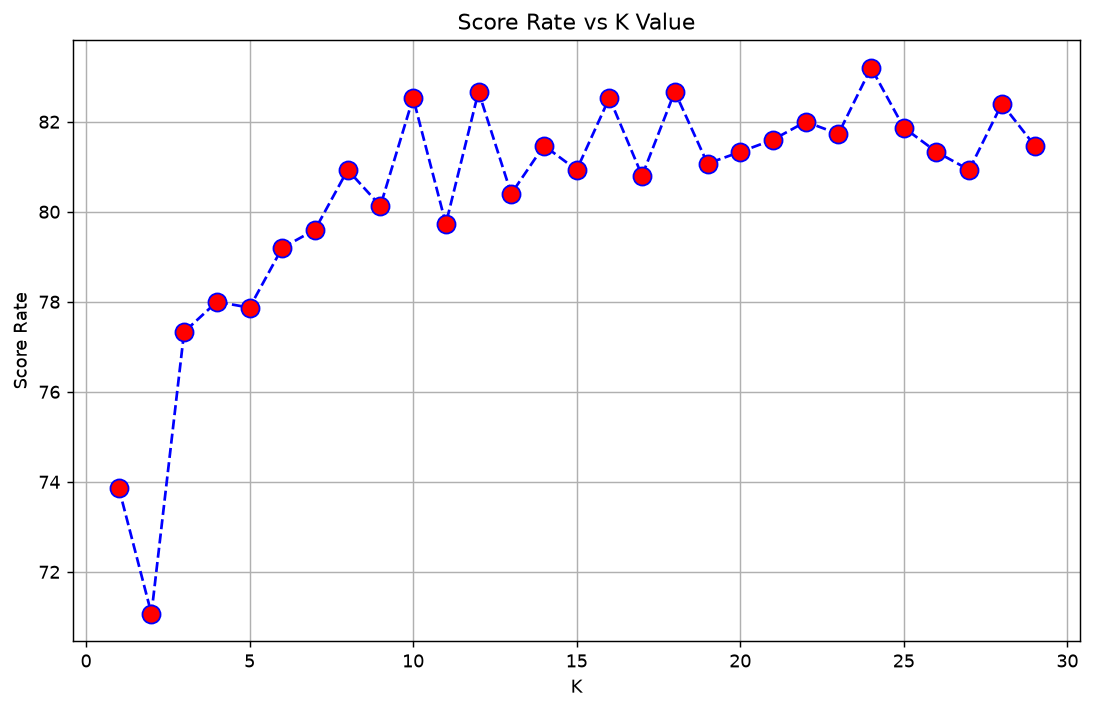

In [63]:
import matplotlib.pyplot as plt

score = []

for i in range(1, 30):
    #model
    model = KNeighborsClassifier(n_neighbors=i, weights='uniform')
    #cross validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=5)
    #score.append(round((cv_scores.mean()*100), 2))
    score.append(round((cv_scores.mean() * 100), 2))

plt.figure(figsize=(10, 6))
plt.plot(range(1, 30), score, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Score Rate vs K Value')
plt.xlabel('K')
plt.ylabel('Score Rate')
plt.grid(True)
plt.show()

Classification Report do modelo treinado com o melhor valor de k

In [64]:
# Encontrar programaticamente o melhor valor de K
melhor_k = score.index(max(score)) + 1
print(f"O melhor valor de K encontrado foi: {melhor_k} com uma acurácia de validação cruzada de {max(score)}%\n")

# Treinar o classificador com este K ótimo
clf_otimo = KNeighborsClassifier(n_neighbors=melhor_k, weights='uniform')
clf_otimo.fit(X_train, y_train)

# Fazer predições no conjunto de teste e exibir o relatório de classificação
y_pred_otimo = clf_otimo.predict(X_test)
print(f"Relatório de Classificação para K={melhor_k}:\n")
print(classification_report(y_test, y_pred_otimo))

O melhor valor de K encontrado foi: 24 com uma acurácia de validação cruzada de 83.2%

Relatório de Classificação para K=24:

              precision    recall  f1-score   support

           0       0.86      0.80      0.83       127
           1       0.81      0.87      0.84       123

    accuracy                           0.84       250
   macro avg       0.84      0.84      0.84       250
weighted avg       0.84      0.84      0.84       250



Matriz de Confusão do Modelo com K Ótimo:


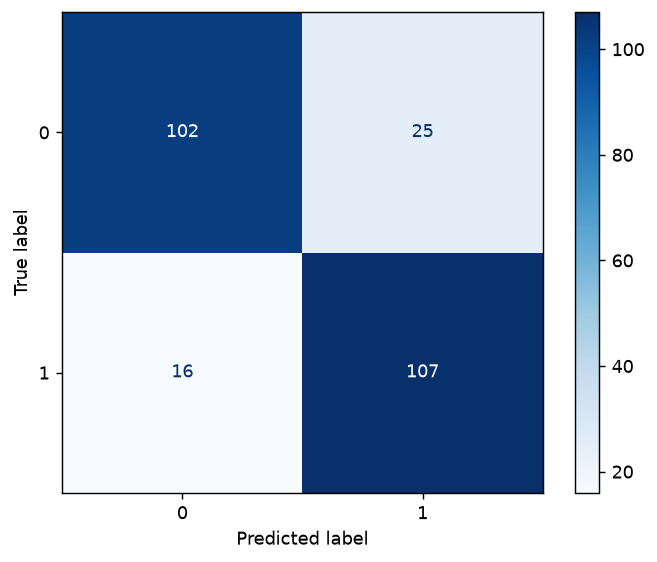

In [65]:
# Gerar a matriz de confusão para o modelo ótimo
print("Matriz de Confusão do Modelo com K Ótimo:")
ConfusionMatrixDisplay.from_estimator(clf_otimo, X_test, y_test, cmap='Blues')
plt.show()

#### Dados **Iris**

Ponto extra

In [66]:
score_iris = []

# Loop de validação cruzada para a base Iris
for i in range(1, 30):
    #model
    model = KNeighborsClassifier(n_neighbors=i, weights='uniform')
    #cross validation
    cv_scores = cross_val_score(model, X_train_iris_scaled, y_train_iris, cv=5)
    #score.append(round((cv_scores.mean()*100), 2))
    score_iris.append(round((cv_scores.mean() * 100), 2))

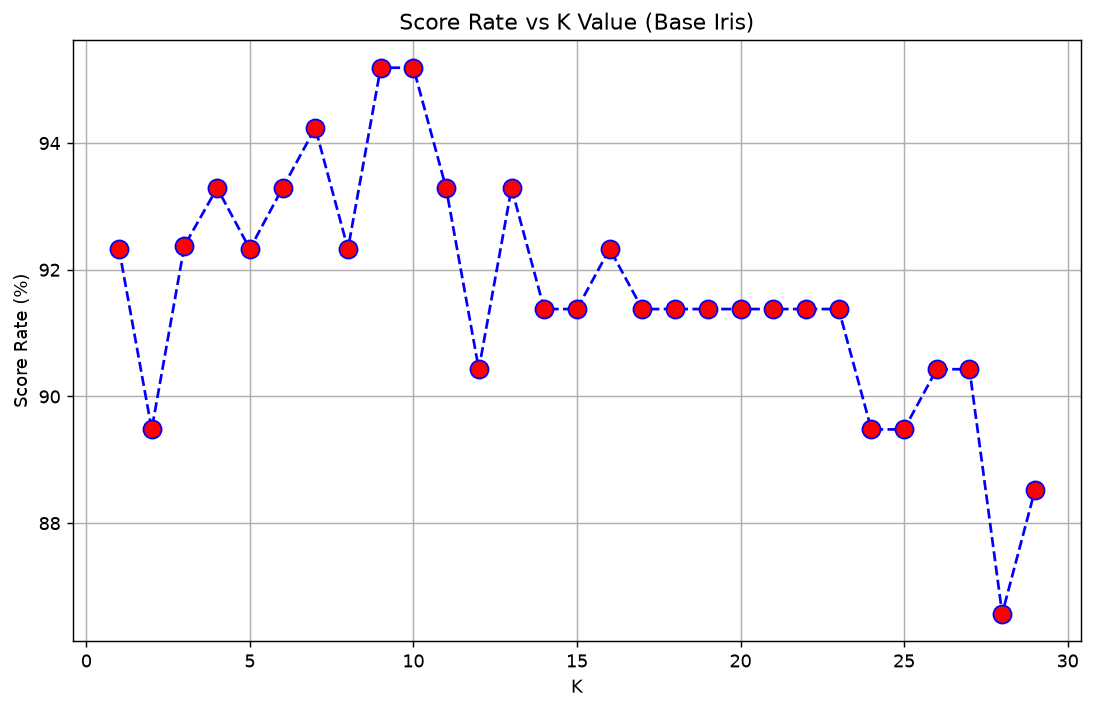

In [67]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 30), score_iris, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Score Rate vs K Value (Base Iris)')
plt.xlabel('K')
plt.ylabel('Score Rate (%)')
plt.grid(True)
plt.show()

In [68]:
# Identificar programaticamente o melhor valor de K para a base Iris
melhor_k_iris = score_iris.index(max(score_iris)) + 1
print(f"O melhor valor de K para a base Iris foi: {melhor_k_iris} com {max(score_iris):.2f}% de acurácia na validação cruzada!")

O melhor valor de K para a base Iris foi: 9 com 95.19% de acurácia na validação cruzada!


Classification Report do modelo treinado com o melhor valor de k

In [69]:
# Treinar o modelo k-NN ótimo para a base Iris
clf_iris_otimo = KNeighborsClassifier(n_neighbors=melhor_k_iris, weights='uniform')
clf_iris_otimo.fit(X_train_iris_scaled, y_train_iris)

# Fazer previsões e gerar o classification report
y_pred_iris_otimo = clf_iris_otimo.predict(X_test_iris_scaled)
print(f"Relatório de Classificação k-NN Iris (K={melhor_k_iris}):\n")
print(classification_report(y_test_iris, y_pred_iris_otimo))

Relatório de Classificação k-NN Iris (K=9):

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        16
           2       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Matriz de Confusão do Modelo Iris com K Ótimo:


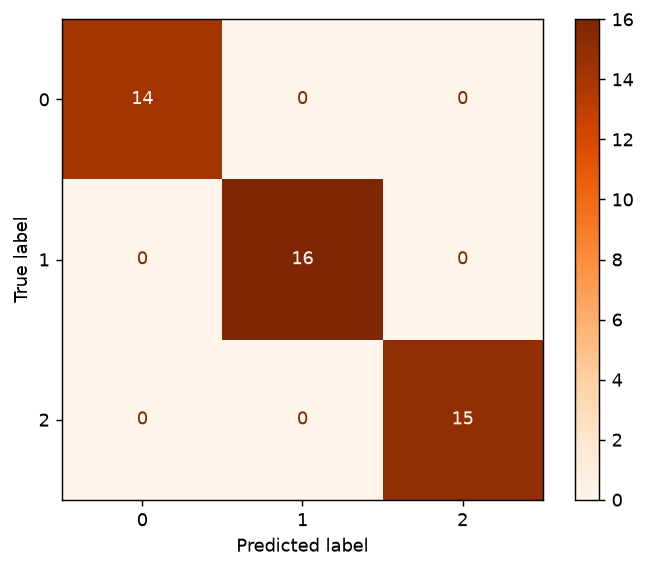

In [70]:
# Gerar a matriz de confusão para o modelo ótimo da Iris
print("Matriz de Confusão do Modelo Iris com K Ótimo:")
ConfusionMatrixDisplay.from_estimator(clf_iris_otimo, X_test_iris_scaled, y_test_iris, cmap='Oranges')
plt.show()

## Conclusão

Descreva o que você identificou como melhoria ou não da utilização das abordagens do PCA, feature selection e Cross Validation.

## Conclusão e Análise dos Experimentos

Com base nos experimentos realizados ao longo deste exercício, podemos extrair as seguintes conclusões sobre a eficácia de cada uma das abordagens utilizadas:

### 1. Redução de Dimensionalidade com PCA
* **Comportamento Observado:** Na base sintética de 20 features originais, a redução de dimensionalidade com o PCA para 5 componentes melhorou sensivelmente a acurácia de validação cruzada do k-NN comparada com as 20 originais (subindo de **77% para 81%**).
* **Vantagens:** O PCA removeu ruídos, correlações e redundâncias presentes nas features sintéticas que atrapalhavam a métrica de distância do k-NN. Isso comprova o efeito positivo do PCA ao mitigar a *maldição da dimensionalidade*.
* **Desvantagens:** Os componentes principais gerados são combinações lineares dos atributos originais, o que acarreta a perda da interpretabilidade física direta das variáveis.

### 2. Seleção de Atributos (Feature Selection) com Random Forest
* **Comportamento Observado:** Na base de dados Iris, o algoritmo Random Forest identificou que apenas dois atributos (`petal_length` e `petal_width`) concentravam mais de **86%** da importância de decisão. Ao treinar o k-NN apenas com essas duas variáveis selecionadas, obtivemos uma acurácia perfeita de **100% no conjunto de teste**.
* **Vantagens:** Diferente do PCA, a seleção de atributos via `SelectFromModel` mantém as variáveis em seu estado original, preservando totalmente a interpretabilidade de qual característica física de fato define o comportamento do modelo (por exemplo, sabendo diretamente que o tamanho e largura da pétala são os fatores cruciais).

### 3. Validação Cruzada (Cross Validation)
* **Comportamento Observado:** O uso da validação cruzada de 5-folds nos permitiu rastrear de forma estatisticamente segura e realista o comportamento de generalização do algoritmo k-NN variando de 1 a 29.
* **Vantagens:** A validação cruzada impediu que tomássemos uma decisão baseada em uma divisão treino-teste de 'sorte'. Ela nos permitiu descobrir com confiança que **K=24** era o ideal para o dataset sintético e *=9* era o ótimo para o dataset Iris, evitando tanto o *overfitting* (com K muito pequeno) quanto o *underfitting* (com K excessivamente grande).